# ChromaVision : résultats publics
## Segmentation couleur, robustesse photométrique et frugalité

**Équipe : Pote Die et Hélène Bobe Douchet.** Contribution équivalente.

Ce notebook utilise uniquement les tableaux de résultats, les modèles et des
graphiques de métriques. Les photographies et les masques du jeu de recherche
restent dans la copie locale. Les résultats proviennent de 15 images de test,
six méthodes et six conditions, soit 540 prédictions.

**Objectif :** comparer les compromis entre recouvrement, robustesse et coût
des méthodes classiques de vision par ordinateur.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = Path.cwd().resolve()
if not (ROOT / "results/summary.csv").exists(): ROOT = ROOT.parent
assert (ROOT / "results/summary.csv").exists(), "Ouvrir le notebook dans le dépôt ChromaVision"
summary = pd.read_csv(ROOT / "results/summary.csv")
predictions = pd.read_csv(ROOT / "results/predictions.csv")
display(json.loads((ROOT / "results/audit.json").read_text()))
print("Lignes de prédiction :", len(predictions))

Lignes de prédiction : 540


{'pairs': 71,
 'exact_pixel_duplicates': 0,
 'dhash_pairs_distance_le_4': 0,
 'mask_threshold': 128,
 'note': 'dHash ne prouve pas l’absence de scènes ou de personnes communes ; pas de métadonnées d’identité'}

## 1. Protocole
71 photographies annotées : 42 pour l'apprentissage, 14 pour la validation,
15 pour le test. Tous les réglages utilisent la validation originale.
Les photographies sont séparées en entier, sans mélange de leurs pixels
entre apprentissage et test. Le plus grand côté est réduit à 320 pixels.

Les modèles comparent une règle RGB, des histogrammes Lab/HS/CrCb,
une correction Gray World et un nettoyage morphologique.

category,FacePhoto,FamilyPhoto
split,,
test,5,10
train,15,27
validation,5,9


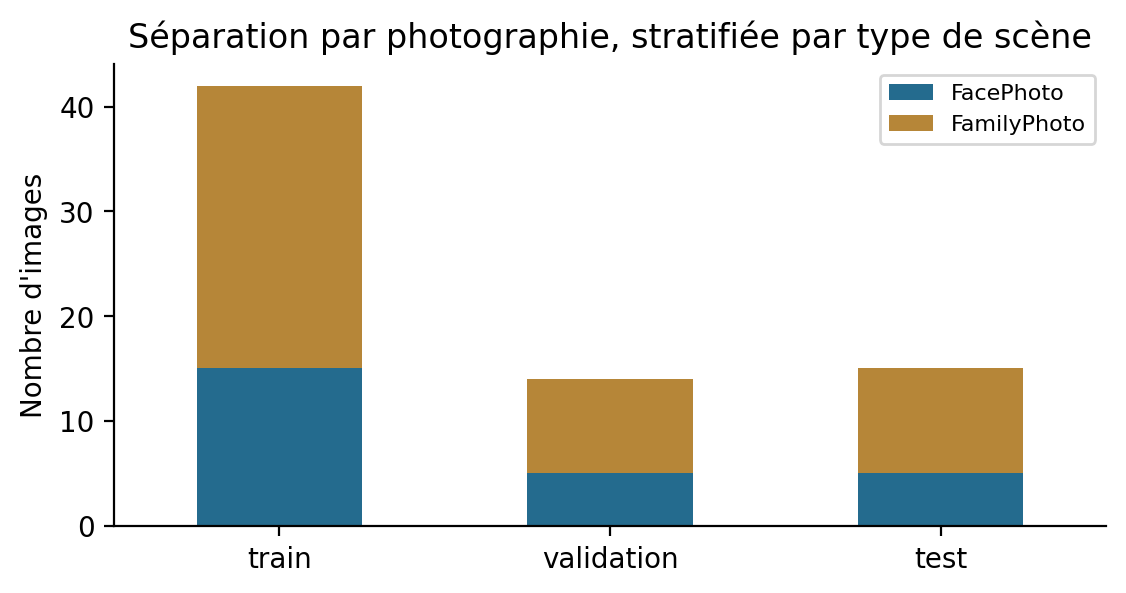

In [2]:
manifest = pd.read_csv(ROOT / "results/manifest_split.csv")
display(manifest.groupby(["split", "category"]).size().unstack())
display(Image(filename=str(ROOT / "results/figures/split.png")))

## 2. Segmentation sur le test original
L'IoU vaut TP/(TP+FP+FN). On la calcule par photographie avant de faire la
moyenne. Les IC à 95 % utilisent 3 000 rééchantillonnages des images à modèles
fixes. Ils ne couvrent pas la variabilité de toutes les séparations possibles.

,method,iou,dice,precision,recall,median_ms
0,RGB-rule,0.428,0.566,0.449,0.881,4.445
3,Lab-Morph,0.416,0.569,0.423,0.957,1.696
5,Hist-CrCb,0.415,0.565,0.424,0.950,1.255
1,GrayWorld-Lab,0.399,0.541,0.539,0.648,3.388
2,Hist-Lab,0.391,0.543,0.396,0.960,1.586
4,Hist-HS,0.379,0.534,0.396,0.878,1.310


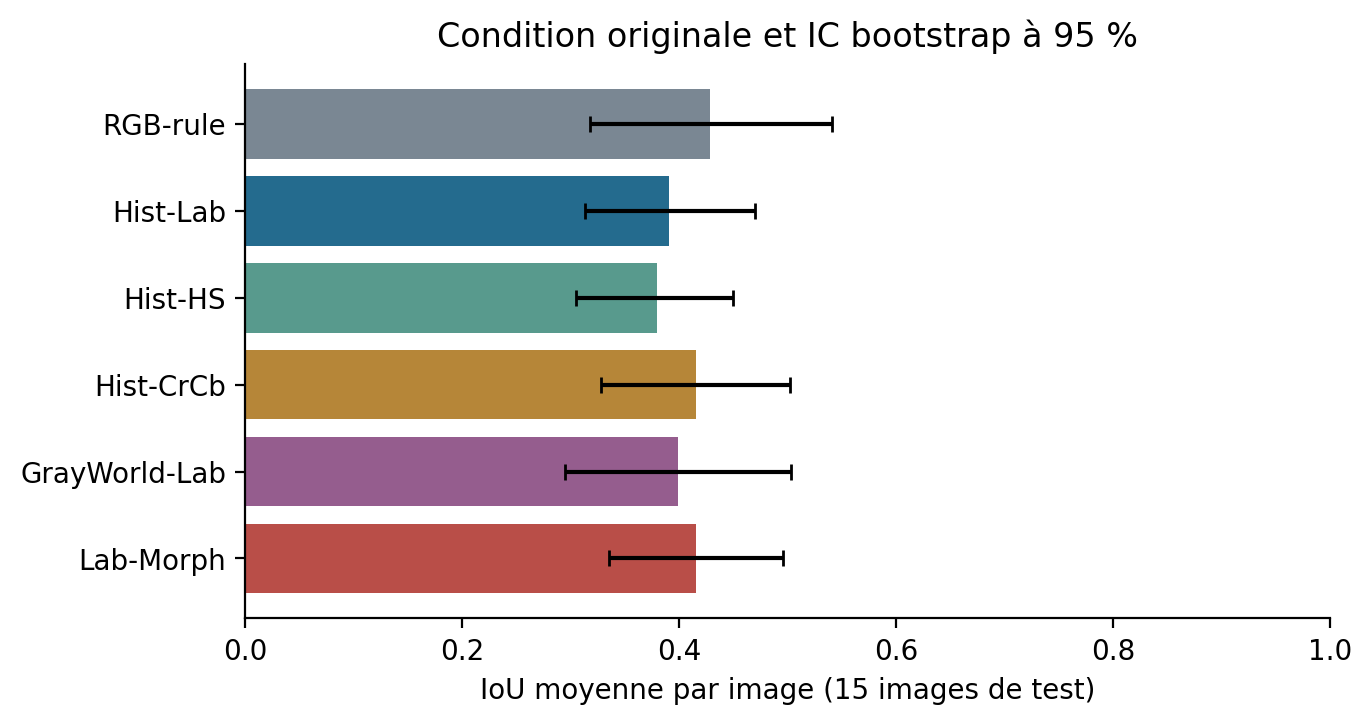

In [3]:
clean = summary[summary.condition == "original"].sort_values("iou", ascending=False)
display(clean[["method", "iou", "dice", "precision", "recall", "median_ms"]].round(3))
display(Image(filename=str(ROOT / "results/figures/clean_iou.png")))

## 3. Robustesse et effets appariés
Les transformations sont appliquées séparément : gamma sombre, gamma clair,
dominante chaude, bruit gaussien et JPEG qualité 35. Le masque reste aligné.
Elles simulent des perturbations, sans remplacer de nouvelles prises de vue.

Les gains de morphologie et de Gray World dépendent de la condition. Aucun
classement universel ou résultat de Deep Learning n'est revendiqué.

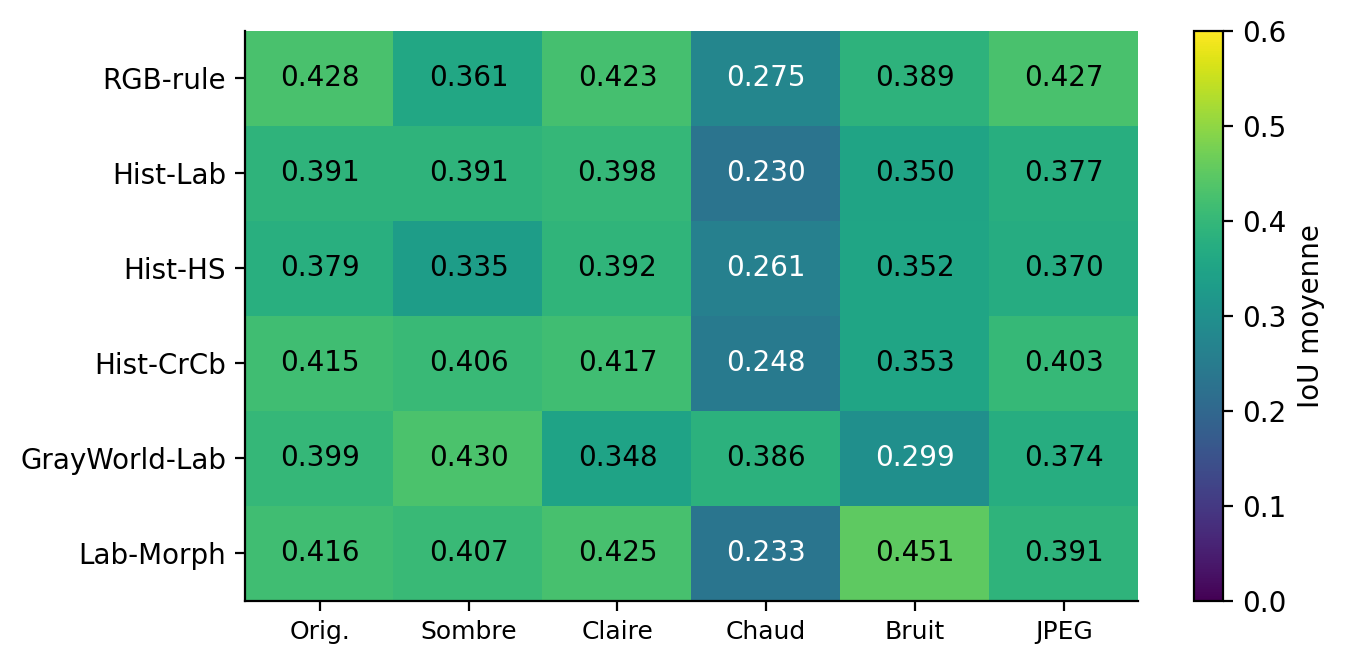

,a,b,condition,delta,low,high
18,GrayWorld-Lab,Hist-Lab,original,0.008,-0.087,0.113
21,GrayWorld-Lab,Hist-Lab,warm,0.156,0.045,0.270
22,GrayWorld-Lab,Hist-Lab,noise,-0.052,-0.119,0.015
24,Lab-Morph,Hist-Lab,original,0.025,0.015,0.035
27,Lab-Morph,Hist-Lab,warm,0.003,0.000,0.006
28,Lab-Morph,Hist-Lab,noise,0.101,0.031,0.167


In [4]:
display(Image(filename=str(ROOT / "results/figures/robustness.png")))
contrasts = pd.read_csv(ROOT / "results/paired_contrasts.csv")
display(contrasts[(contrasts.a.isin(["Lab-Morph", "GrayWorld-Lab"])) &
                  contrasts.condition.isin(["original", "noise", "warm"])].round(3))

## 4. Coût de calcul et mémoire
La latence inclut la conversion couleur et le post-traitement mais exclut
la lecture du fichier. OpenCV utilise un thread. Trois mesures suivent
un échauffement. Les temps sont ceux de l'environnement livré.

La LUT d'un histogramme occupe 4 Kio. La RSS mesurée du processus inclut
Python et OpenCV, dépasse 100 Mio et peut manquer un pic très bref.

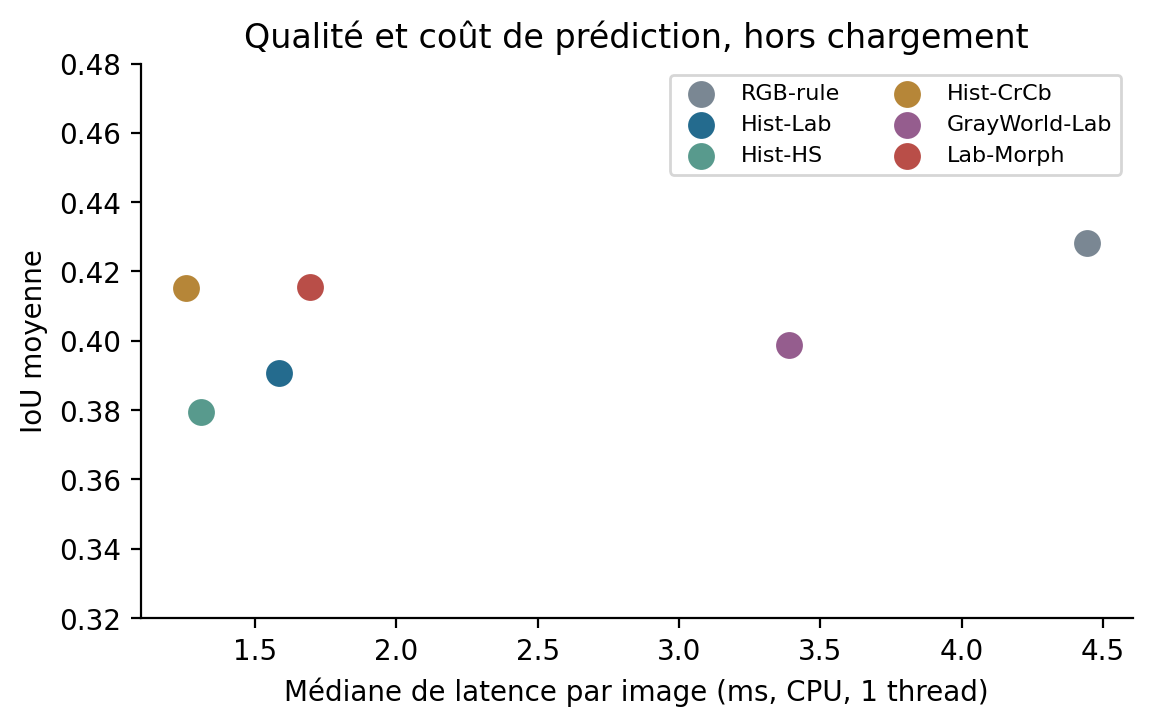

,method,model_bytes,sampled_peak_rss_mib
0,GrayWorld-Lab,4096,112.14
1,Hist-CrCb,4096,111.35
2,Hist-HS,4096,110.32
3,Hist-Lab,4096,112.08
4,Lab-Morph,4096,114.33
5,RGB-rule,0,113.30


In [5]:
display(Image(filename=str(ROOT / "results/figures/quality_latency.png")))
memory = pd.read_csv(ROOT / "results/memory.csv")
display(memory[["method", "model_bytes", "sampled_peak_rss_mib"]].round(2))

## 5. Efficacité en données
Chaque budget de 4, 12, 24 ou 42 images refait son apprentissage et ses choix
sur les mêmes 14 images de validation. Trois sous-échantillonnages montrent
la variabilité. Le budget 42 utilise les mêmes données à chaque tirage.
Le petit test ne permet pas d'affirmer que 24 images sont un optimum.

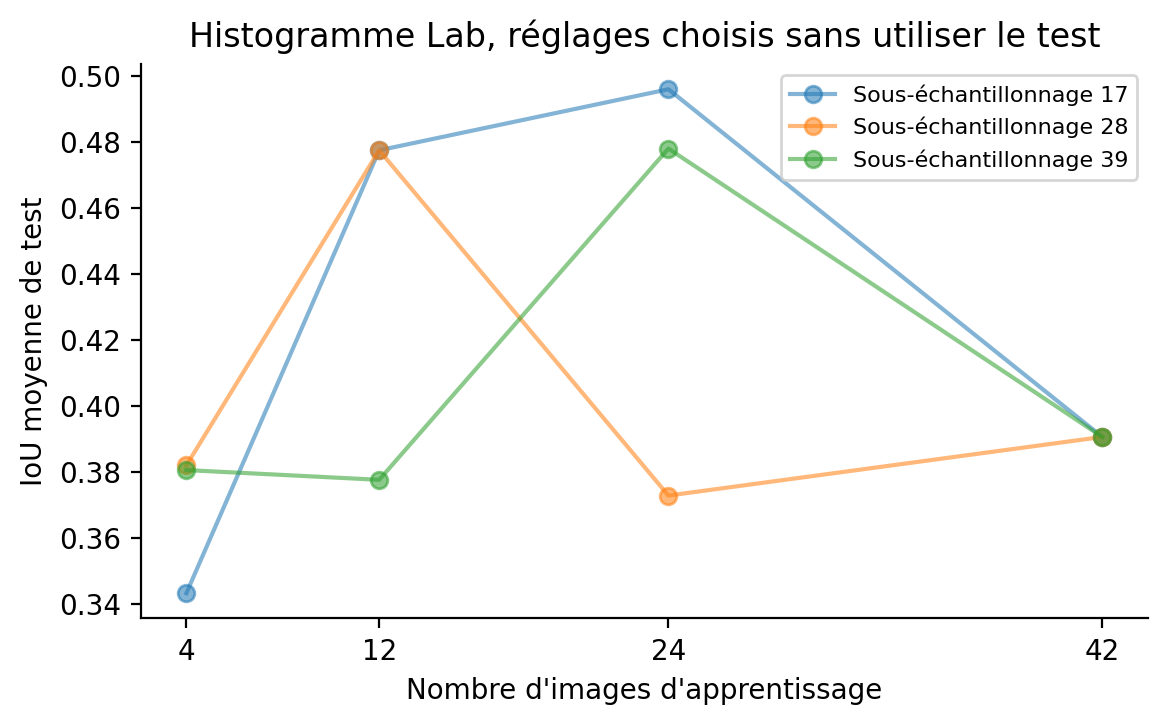

seed,17,28,39
budget,,,
4,0.343,0.382,0.381
12,0.477,0.477,0.378
24,0.496,0.373,0.478
42,0.391,0.391,0.391


In [6]:
display(Image(filename=str(ROOT / "results/figures/data_efficiency.png")))
efficiency = pd.read_csv(ROOT / "results/data_efficiency.csv")
display(efficiency.groupby(["budget", "seed"]).iou.mean().unstack().round(3))

## 6. Recalculer les métriques sans les photographies
Les comptes TP, FP, FN et TN permettent de contrôler les scores exportés.
Cette vérification ne remplace pas la réexécution de l'inférence sur les
images originales. Le script `scripts/verify_results.py` vérifie aussi les
partitions, les modèles figés et les contrastes.

In [7]:
assert len(predictions) == 540
assert not predictions.duplicated(["id", "method", "condition"]).any()
np.testing.assert_allclose(predictions.iou,
    predictions.tp / (predictions.tp + predictions.fp + predictions.fn), atol=1e-12)
np.testing.assert_allclose(predictions.dice,
    2 * predictions.tp / (2 * predictions.tp + predictions.fp + predictions.fn), atol=1e-12)
print("Métriques des 540 lignes de prédiction cohérentes avec les comptes de pixels.")

Métriques des 540 lignes de prédiction cohérentes avec les comptes de pixels.


## Conclusion
La couleur permet des modèles compacts et interprétables mais manque de
contexte sémantique. Une règle simple reste compétitive sur le test original.
Les améliorations observées sont ciblées et doivent être confirmées sur
d'autres scènes. Le projet démontre une démarche expérimentale reproductible.

Références : cours de vision par ordinateur fournis, Tan et al. (2012),
Jones et Rehg (2002), Kakumanu et al. (2007), documentation OpenCV.
Sources et conditions des données dans `REFERENCES.md` et `DATA_POLICY.md`.